# 03 — Dari model ke produk: tuning, uji ketahanan, deployment, monitoring

`02_modeling.ipynb` menghasilkan model yang bagus **di atas kertas**. Notebook ini menjawab pertanyaan yang muncul sebelum model boleh dipakai sungguhan:

1. Apakah hyperparameter tuning membantu?
2. Seberapa bagus model menghadapi **situs judi baru** yang belum pernah dilihat?
3. Bagaimana model dipakai aplikasi lain? (REST API)
4. Bagaimana tahu kalau model mulai memburuk setelah dipakai? (monitoring)

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd, matplotlib.pyplot as plt
from src.config import DATA_PATH, TEXT_COL, LABEL_COL
from src.preprocessing import load_data, clean_data, normalize_text
from src.model import split_data, tune_model, PARAM_GRID
%matplotlib inline
df = clean_data(load_data(DATA_PATH))
X_train, X_test, y_train, y_test = split_data(df[TEXT_COL], df[LABEL_COL])

## 1. Hyperparameter tuning
`GridSearchCV` mencoba semua kombinasi di `PARAM_GRID`, masing-masing dengan 5-fold CV di **train set saja**.

In [2]:
PARAM_GRID

{'clf__C': [1, 10, 30],
 'features__word__ngram_range': [(1, 1), (1, 2)],
 'features__char__ngram_range': [(2, 5), (3, 6)]}

In [3]:
search = tune_model(X_train, y_train)
res = pd.DataFrame(search.cv_results_)
cols = ['param_clf__C', 'param_features__word__ngram_range', 'param_features__char__ngram_range', 'mean_test_score', 'std_test_score']
res[cols].sort_values('mean_test_score', ascending=False).round(4)

,param_clf__C,param_features__word__ngram_range,param_features__char__ngram_range,mean_test_score,std_test_score
9,30,"(1, 2)","(2, 5)",0.9820,0.0061
5,10,"(1, 2)","(2, 5)",0.9818,0.0067
4,10,"(1, 1)","(2, 5)",0.9816,0.0065
8,30,"(1, 1)","(2, 5)",0.9814,0.0066
7,10,"(1, 2)","(3, 6)",0.9812,0.0057
6,10,"(1, 1)","(3, 6)",0.9810,0.0059
11,30,"(1, 2)","(3, 6)",0.9810,0.0076
10,30,"(1, 1)","(3, 6)",0.9808,0.0066
0,1,"(1, 1)","(2, 5)",0.9800,0.0052
1,1,"(1, 2)","(2, 5)",0.9794,0.0056


In [4]:
print('terbaik :', search.best_params_, round(search.best_score_, 4))
default = res[(res.param_clf__C == 10) & (res.param_features__word__ngram_range == (1, 2)) & (res.param_features__char__ngram_range == (2, 5))]
print('default :', round(float(default.mean_test_score.iloc[0]), 4), '± ', round(float(default.std_test_score.iloc[0]), 4))

terbaik : {'clf__C': 30, 'features__char__ngram_range': (2, 5), 'features__word__ngram_range': (1, 2)} 0.982
default : 0.9818 ±  0.0067


**Pelajaran:** selisih antara kombinasi terbaik dan setting default jauh lebih kecil dari std-nya. Tuning **tidak** memberi peningkatan yang berarti di sini, jadi kita tetap memakai default yang lebih sederhana. Tuning bukan sihir: kalau feature-nya sudah bagus, ruang untuk naik kecil.

## 2. Uji ketahanan: situs judi yang belum pernah dilihat
Di split acak, komentar tentang `alexis17` ada di train **dan** test, jadi model bisa menghafal nama situs. Di dunia nyata, spammer terus membuat situs baru. Simulasinya: untuk tiap situs, latih tanpa komentar yang menyebut situs itu, lalu uji pada komentar situs tersebut.

In [5]:
from src.robustness import find_brands, brand_holdout
norm = df[TEXT_COL].map(normalize_text)
brands = find_brands(norm, df[LABEL_COL])
robust = brand_holdout(df, brands)
robust

  alexis       n=1029 recall on unseen brand = 0.858


  mandalika    n=305  recall on unseen brand = 0.997


  dora         n=217  recall on unseen brand = 0.986


  weton        n=100  recall on unseen brand = 1.000


  pluto        n=60   recall on unseen brand = 1.000


  pulau        n=165  recall on unseen brand = 0.770


  manut        n=45   recall on unseen brand = 1.000


  berkah       n=52   recall on unseen brand = 0.981


,held_out_brand,n_test,recall_unseen
0,alexis,1029,0.858115
1,mandalika,305,0.996721
2,dora,217,0.986175
3,weton,100,1.000000
4,pluto,60,1.000000
5,pulau,165,0.769697
6,manut,45,1.000000
7,berkah,52,0.980769


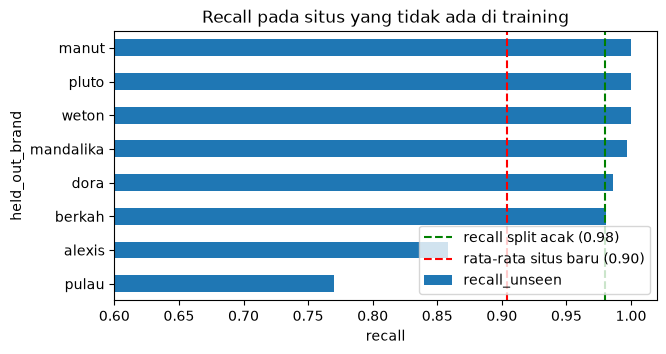

In [6]:
weighted = (robust.recall_unseen * robust.n_test).sum() / robust.n_test.sum()
ax = robust.set_index('held_out_brand').recall_unseen.sort_values().plot.barh(figsize=(7, 3.5))
ax.axvline(0.98, color='green', ls='--', label='recall split acak (0.98)')
ax.axvline(weighted, color='red', ls='--', label=f'rata-rata situs baru ({weighted:.2f})')
ax.set_xlim(0.6, 1.02); ax.set_xlabel('recall'); ax.legend(loc='lower right'); ax.set_title('Recall pada situs yang tidak ada di training');

Kenapa `pulau` paling sulit? Lihat contoh komentarnya: banyak yang menulis `pulauwin` **tanpa angka**, sehingga feature `brand_number_count` tidak menyala dan polanya mirip kata biasa.

In [7]:
df[norm.str.contains('pulau') & (df[LABEL_COL] == 1)][TEXT_COL].sample(8, random_state=1).tolist()

['kalo bukan ＰＵＬＡＵＷＩＮ yg kasih duit siapa lagi',
 'gue suka penasaran , 𝙋𝙐𝙇𝘼𝙐𝙒𝙄𝙉 sedominan ?',
 'gue pikir hype , 𝓟𝓤𝓛𝓐𝓤𝓦𝓘𝓝 rame .',
 'IYA EMG MANTAP BRO P U L A U 7 7 7 LGSG CARI AZ',
 '03:25 p u l a u w i n bikin penasaran',
 '06:30 P U L A U W I N bahaya buat orang ketagihan',
 '19:30 Pulau 777 – Menang besar, hadiahnya luar biasa!',
 'Enak bgt main di 𝓟 𝓤 𝓛 𝓐 𝓤 𝓦 𝓘 𝓝 😆']

**Pelajaran:** skor test 0,98 terlalu optimis untuk situs baru; angka realistisnya ~0,90. Selalu tanya: *apakah test set saya benar-benar mirip dengan data masa depan?*

## 3. Deployment: model sebagai REST API
`src/api.py` membungkus model dengan FastAPI. Di terminal, jalankan `uvicorn src.api:app --reload` lalu buka http://127.0.0.1:8000. Di sini kita memanggilnya langsung lewat `TestClient` tanpa menyalakan server.

In [8]:
import src.api as api
from fastapi.testclient import TestClient
api.PREDICTION_LOG_PATH = ROOT / 'logs' / 'notebook_demo.jsonl'
api.PREDICTION_LOG_PATH.unlink(missing_ok=True)
with TestClient(api.app) as client:
    print(client.get('/health').json())
    r = client.post('/predict', json={'texts': ['mantap videonya bang', 'wd lancar di Ｐｕｌａｕ７７７', 'harga mobilnya berapa?']})
r.json()

{'status': 'ok', 'model_loaded': True}


C:\Users\Brian\Documents\Projects\online-gambling-ml-analysis-main\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


{'model_version': '20261021-160319',
 'predictions': [{'text': 'mantap videonya bang',
   'label': 'normal',
   'score': 0.0014},
  {'text': 'wd lancar di Ｐｕｌａｕ７７７', 'label': 'judol', 'score': 1.0},
  {'text': 'harga mobilnya berapa?', 'label': 'normal', 'score': 0.001}]}

## 4. Monitoring
Model tidak rusak dengan suara keras; performanya **diam-diam** turun saat data berubah. API mencatat setiap prediksi (hanya hash teks, bukan komentarnya). `src/monitor.py` membandingkan log dengan baseline saat training.

Simulasi: kirim gelombang spam dengan gaya penyamaran baru.

In [9]:
gelombang = ['coba main di ᴋ ɪ ɴ ɢ 𝟿𝟿 auto jp', 'mantap videonya', 'ᴋɪɴɢ𝟿𝟿 wd cepet bgt', 'kapan review mobil listrik?',
             'cuan terus bareng ᴋɪɴɢ𝟿𝟿', 'join ᴋɪɴɢ𝟿𝟿 skrg', 'bagus bang kontennya', 'ᴋɪɴɢ𝟿𝟿 gacor parah']
with TestClient(api.app) as client:
    client.post('/predict', json={'texts': gelombang})
from src.monitor import load_log, summarize
info = json.loads((ROOT / 'models' / 'model_info.json').read_text())
summary, warnings = summarize(load_log(api.PREDICTION_LOG_PATH), info['baseline'])
print(json.dumps(summary, indent=2))
for w in warnings: print('WARNING:', w)

{
  "n_predictions": 11,
  "judol_rate": 0.5454545454545454,
  "baseline_judol_rate": 0.32815102720710715,
  "uncertain_share": 0.0,
  "median_score": 0.971687,
  "model_versions": [
    "20261021-160319"
  ]
}


Kalau warning muncul terus-menerus, siklus **retraining**:
1. Ambil sampel komentar terbaru, beri label manual
2. Tambahkan ke dataset → `python -m src.train`
3. Bandingkan metrik dengan `model_info.json` lama; ganti model hanya kalau lebih baik
4. Deploy ulang (build Docker image baru)

In [10]:
api.PREDICTION_LOG_PATH.unlink(missing_ok=True)  # bersihkan file demo

## Ringkasan siklus hidup proyek ML
```
masalah → data → EDA → cleaning → feature → model → validasi → evaluasi → error analysis
   ↑                                                                                  ↓
retrain ← monitoring ← deployment (API + Docker) ← model card ← uji ketahanan ← tuning
```